# Experiments 02 & 03 — Sine Wave: Linear Layer vs. MLP

The interactive companion to `experiments/02_sine_wave_linear/` and
`experiments/03_sine_wave_mlp/`, side by side.

**The story:** take the *same* curvy data (`y = sin(x)`) and the *same* training
loop, and change only the model.

| model | outcome |
|-------|---------|
| `Linear(1,1)` | **fails** — a line can't bend (loss ~0.41) |
| `Linear(1,64) → ReLU → Linear(64,1)` | **fits** — loss drops to the noise floor |

The single variable that changes is **nonlinearity**. That's the whole lesson.


In [1]:
import sys
from pathlib import Path

import torch
from torch import nn
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils import set_seed, get_device

# Override the Agg backend that utils.plotting sets, so plots render inline here.
%matplotlib inline

set_seed(42)
device = get_device()
print("device:", device)

device: cpu


## The data — a sine wave

Two full periods of `sin(x)` with a little noise. This is a *curve*: no straight
line can describe it.

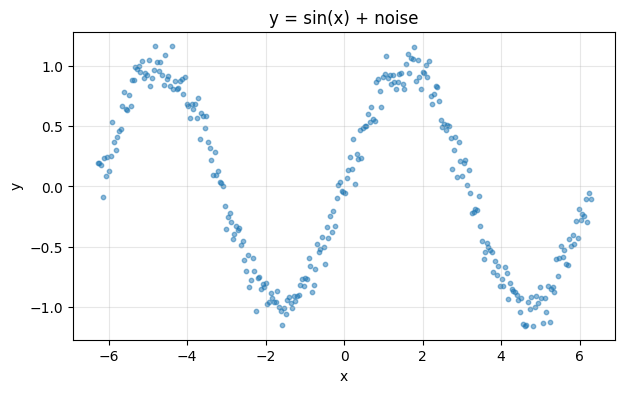

In [2]:
N, NOISE = 300, 0.1
x = torch.linspace(-2 * torch.pi, 2 * torch.pi, N, device=device).unsqueeze(1)
y = torch.sin(x) + torch.randn(N, 1, device=device) * NOISE

plt.figure(figsize=(7, 4))
plt.scatter(x.cpu(), y.cpu(), s=10, alpha=0.5)
plt.title("y = sin(x) + noise"); plt.xlabel("x"); plt.ylabel("y"); plt.grid(alpha=0.3)
plt.show()

In [3]:
# Shuffle before splitting (data is sorted by x), then 80/20 train/val.
perm = torch.randperm(N, device=device)
x, y = x[perm], y[perm]
n_val = N // 5
x_train, y_train = x[:-n_val], y[:-n_val]
x_val,   y_val   = x[-n_val:], y[-n_val:]
x_train.shape, x_val.shape

(torch.Size([240, 1]), torch.Size([60, 1]))

A tiny helper so we run the *identical* loop for both models — only the model
and inputs differ.

In [4]:
def train(model, xtr, ytr, xva, yva, epochs, lr):
    loss_fn = nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train": [], "val": []}
    for _ in range(epochs):
        model.train()
        loss = loss_fn(model(xtr), ytr)
        opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            vloss = loss_fn(model(xva), yva)
        hist["train"].append(loss.item()); hist["val"].append(vloss.item())
    return hist

## Part A — a single linear layer (experiment 02)

`nn.Linear(1,1)` computes `w·x + b`. It has no way to bend, so the best it can do
is a near-flat line through the middle of the wave.

In [5]:
lin = nn.Linear(1, 1).to(device)
hist_lin = train(lin, x_train, y_train, x_val, y_val, epochs=800, lr=0.05)
print(f"final train loss: {hist_lin['train'][-1]:.4f}   (a flat line scores ~0.5)")

final train loss: 0.4123   (a flat line scores ~0.5)


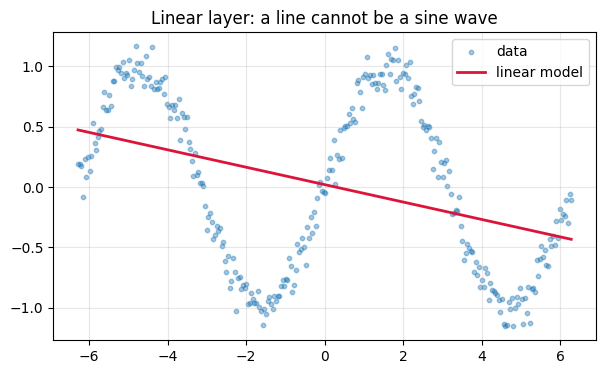

In [6]:
with torch.no_grad():
    xs = torch.linspace(-2*torch.pi, 2*torch.pi, 300, device=device).unsqueeze(1)
    ys_lin = lin(xs)

plt.figure(figsize=(7, 4))
plt.scatter(x.cpu(), y.cpu(), s=10, alpha=0.4, label="data")
plt.plot(xs.cpu(), ys_lin.cpu(), color="crimson", lw=2, label="linear model")
plt.title("Linear layer: a line cannot be a sine wave")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Part B — an MLP with a hidden layer + ReLU (experiment 03)

Same loop, new model: `Linear(1→64) → ReLU → Linear(64→1)`.

Two practical tweaks that make it train well: **Adam** (faster than SGD here) and
**standardizing x** (centering inputs to mean 0 / std 1 speeds optimization).

In [7]:
# Standardize x using TRAIN stats only (using val stats would leak info).
x_mean, x_std = x_train.mean(), x_train.std()
x_train_n = (x_train - x_mean) / x_std
x_val_n   = (x_val   - x_mean) / x_std

mlp = nn.Sequential(
    nn.Linear(1, 64),
    nn.ReLU(),
    nn.Linear(64, 1),
).to(device)
print("params:", sum(p.numel() for p in mlp.parameters()))

hist_mlp = train(mlp, x_train_n, y_train, x_val_n, y_val, epochs=3000, lr=0.01)
print(f"final train loss: {hist_mlp['train'][-1]:.4f}   (noise floor ~{NOISE**2:.4f})")

params: 193


final train loss: 0.0095   (noise floor ~0.0100)


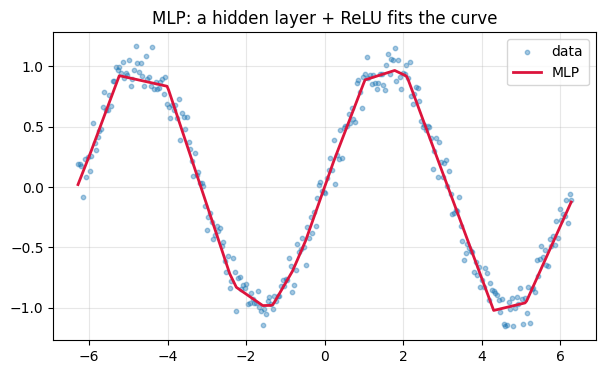

In [8]:
with torch.no_grad():
    ys_mlp = mlp((xs - x_mean) / x_std)

plt.figure(figsize=(7, 4))
plt.scatter(x.cpu(), y.cpu(), s=10, alpha=0.4, label="data")
plt.plot(xs.cpu(), ys_mlp.cpu(), color="crimson", lw=2, label="MLP")
plt.title("MLP: a hidden layer + ReLU fits the curve")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Notice the fit is made of short straight segments with **kinks** — that's
literally how a ReLU network builds a curve: by stitching together many bent
lines. More hidden units → more bends → smoother fit. (Try changing `64`.)

## Side by side — loss curves

Same data, same loop. The only difference is whether the model can bend.

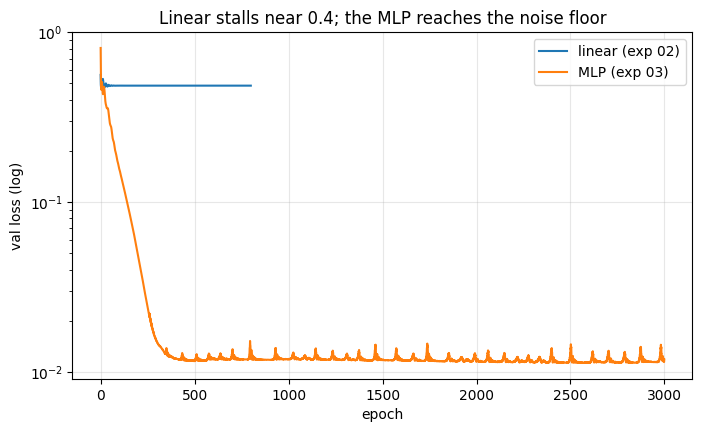

In [9]:
plt.figure(figsize=(8, 4.5))
plt.plot(hist_lin["val"], label="linear (exp 02)")
plt.plot(hist_mlp["val"], label="MLP (exp 03)")
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("val loss (log)")
plt.title("Linear stalls near 0.4; the MLP reaches the noise floor")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Takeaways

- A linear model **cannot** represent a nonlinear function — that's a capacity
  limit, not a training-time problem. More epochs won't help.
- A **nonlinearity between linear layers** (here, ReLU) is what unlocks curves.
  Without it, stacked linear layers collapse back to a single linear map.
- A ReLU MLP approximates a curve as **piecewise-linear** segments — visible as
  the kinks in the fit.
- Same training loop throughout — only the model changed. Architecture is the
  lever here.

**Next:** optimization (SGD vs Adam, learning-rate sweeps, mini-batching with
`DataLoader`), then generalization (overfitting, regularization).